# Classification des anomalies : EfficientNet-B0
Suite de **3data_preparation.ipynb**. On classe l'anomalie (animals / obstacles / cones) à partir d'un **recadrage autour de l'anomalie**,
avec le transfer learning d'EfficientNet-B0 (ImageNet).

Plan : recadrage → GridSearch de la tête → entraînement 1 (tête seule) → entraînement 2 (derniers blocs + early stopping) → courbes → validation.

## 0. Imports et données

In [1]:
import os, copy, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", DEVICE)

DOSSIER = r"C:\Users\MSI\Desktop\RoadAnomaly"
if not os.path.isdir(os.path.join(DOSSIER, "frames")):
    DOSSIER = os.path.join(DOSSIER, "RoadAnomaly")
PREP = os.path.join(DOSSIER, "frames", "DataPreparation")

CLASSES = ["animals", "obstacles", "cones"]
etiq = pd.read_csv(f"{PREP}/etiquettes.csv")
etiq["y"] = etiq["classe"].map({c: i for i, c in enumerate(CLASSES)})
pd.crosstab(etiq["ensemble"], etiq["classe"], margins=True)

Device : cuda


classe,animals,cones,obstacles,All
ensemble,,,,
test,54,42,67,163
train,227,249,222,698
val,53,42,44,139
All,334,333,333,1000


## 1. Recadrage autour de l'anomalie
Le masque 0 / 1 donne la boîte de l'anomalie. On découpe un **carré centré sur cette boîte** (+ 15 % de marge), puis on redimensionne en **224 × 224**
(taille native d'EfficientNet-B0). Le modèle voit l'objet, pas toute la route.
Pas d'augmentation ici : elle est déjà faite dans DataAugmentation. La normalisation ImageNet se fait au chargement.

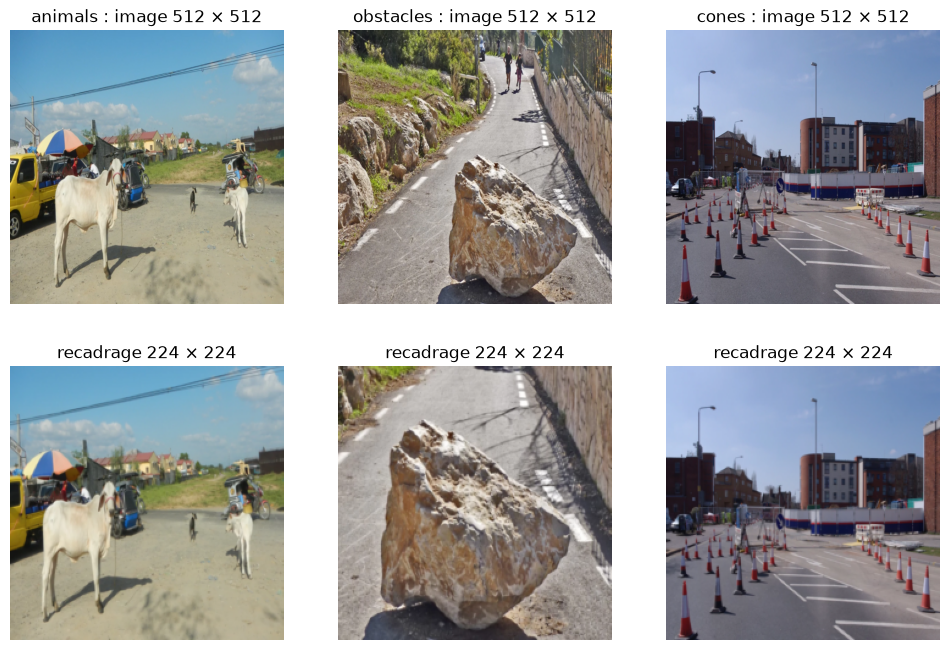

In [2]:
TAILLE = 224
MARGE = 0.15

def recadrer(nom, e):
    img = Image.open(f"{PREP}/{e}/images/{nom}.png").convert("RGB")
    masque = np.array(Image.open(f"{PREP}/{e}/masques/{nom}.png"))
    H, W = masque.shape
    ys, xs = np.where(masque == 1)
    if len(ys) == 0:                                   # sécurité : pas d'anomalie visible -> image entière
        return img.resize((TAILLE, TAILLE), Image.BILINEAR)
    cote = int(max(ys.max() - ys.min(), xs.max() - xs.min()) * (1 + 2 * MARGE))
    cote = min(max(cote, 32), min(H, W))
    cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
    x0 = int(np.clip(cx - cote / 2, 0, W - cote))
    y0 = int(np.clip(cy - cote / 2, 0, H - cote))
    return img.crop((x0, y0, x0 + cote, y0 + cote)).resize((TAILLE, TAILLE), Image.BILINEAR)

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for j, c in enumerate(CLASSES):
    nom = etiq[(etiq.ensemble == "train") & (etiq.classe == c)].nom.iloc[0]
    ax[0, j].imshow(Image.open(f"{PREP}/train/images/{nom}.png")); ax[0, j].set_title(f"{c} : image 512 × 512")
    ax[1, j].imshow(recadrer(nom, "train")); ax[1, j].set_title("recadrage 224 × 224")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.show()

In [3]:
def charger_ensemble(e):
    d = etiq[etiq.ensemble == e]
    X = np.stack([np.array(recadrer(n, e)) for n in d.nom])
    X = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()      # uint8, (N, 3, 224, 224)
    return X, torch.tensor(d.y.values)

Xtr, ytr = charger_ensemble("train")
Xva, yva = charger_ensemble("val")
Xte, yte = charger_ensemble("test")
print("train", tuple(Xtr.shape), "| val", tuple(Xva.shape), "| test", tuple(Xte.shape))

MOY = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
ECART = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
def normaliser(x):
    return (x.to(DEVICE).float() / 255 - MOY) / ECART           # normalisation ImageNet

def loader(X, y, batch, shuffle):
    return DataLoader(TensorDataset(X, y), batch_size=batch, shuffle=shuffle)

val_loader = loader(Xva, yva, 32, False)
test_loader = loader(Xte, yte, 32, False)

train (698, 3, 224, 224) | val (139, 3, 224, 224) | test (163, 3, 224, 224)


## 2. Création du modèle
EfficientNet-B0 pré-entraîné sur ImageNet. On remplace le classifieur par une petite tête : `Linear(1280 → 256)` → `ReLU` → `Dropout` → `Linear(256 → 3)`.
Le reste du réseau apporte `Conv2d`, `SiLU` et `AdaptiveAvgPool2d`.

In [4]:
def creer_modele(dropout=0.3, hidden=256):
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier = nn.Sequential(
        nn.Linear(1280, hidden), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden, len(CLASSES))
    )
    return m.to(DEVICE)

modele = creer_modele()
types = {type(l).__name__ for l in modele.modules()}
for t in ["Conv2d", "SiLU", "AdaptiveAvgPool2d", "Linear", "ReLU"]:
    print(f"{t:18s}", "OK" if t in types else "absent")
print("\nTête :", modele.classifier)
print("Paramètres :", sum(p.numel() for p in modele.parameters()))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\MSI/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:08<00:00, 2.39MB/s]


Conv2d             OK
SiLU               OK
AdaptiveAvgPool2d  OK
Linear             OK
ReLU               OK

Tête : Sequential(
  (0): Linear(in_features=1280, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=3, bias=True)
)
Paramètres : 4336255


## 3. Fonctions d'entraînement
- **Optimiseur Adam**, perte `CrossEntropyLoss` (classes équilibrées).
- Les couches gelées restent en mode `eval` : leurs statistiques BatchNorm ne bougent pas.
- **Early stopping** : arrêt si la perte de validation ne baisse plus pendant `patience` époques, puis retour aux meilleurs poids.

In [5]:
critere = nn.CrossEntropyLoss()

def geler_sauf_tete(m):
    for p in m.features.parameters(): p.requires_grad = False
    for p in m.classifier.parameters(): p.requires_grad = True

def degeler_derniers_blocs(m, n):
    for b in m.features[-n:]:
        for p in b.parameters(): p.requires_grad = True

def mode_train(m, n_blocs):
    m.eval()
    m.classifier.train()
    if n_blocs:
        for b in m.features[-n_blocs:]: b.train()

def optimiseur(m, lr):
    return torch.optim.Adam([p for p in m.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)

def une_epoque(m, dl, opt, n_blocs):
    mode_train(m, n_blocs)
    perte, ok, n = 0, 0, 0
    for x, y in dl:
        x, y = normaliser(x), y.to(DEVICE)
        opt.zero_grad()
        sortie = m(x)
        l = critere(sortie, y)
        l.backward(); opt.step()
        perte += l.item() * len(y); ok += (sortie.argmax(1) == y).sum().item(); n += len(y)
    return perte / n, ok / n

@torch.no_grad()
def evaluer(m, dl):
    m.eval()
    perte, preds, vrais = 0, [], []
    for x, y in dl:
        sortie = m(normaliser(x))
        perte += critere(sortie, y.to(DEVICE)).item() * len(y)
        preds.append(sortie.argmax(1).cpu()); vrais.append(y)
    preds, vrais = torch.cat(preds).numpy(), torch.cat(vrais).numpy()
    return perte / len(vrais), (preds == vrais).mean(), preds, vrais

def entrainer(m, dl_train, opt, epoques, n_blocs=0, patience=None, phase=""):
    historique, meilleur, meilleurs_poids, sans_progres = [], np.inf, None, 0
    for ep in range(1, epoques + 1):
        tr_l, tr_a = une_epoque(m, dl_train, opt, n_blocs)
        va_l, va_a, _, _ = evaluer(m, val_loader)
        historique.append(dict(phase=phase, train_loss=tr_l, val_loss=va_l, train_acc=tr_a, val_acc=va_a))
        print(f"[{phase}] époque {ep:2d}  perte {tr_l:.4f} / {va_l:.4f}   accuracy {tr_a:.3f} / {va_a:.3f}")
        if patience:
            if va_l < meilleur:
                meilleur, meilleurs_poids, sans_progres = va_l, copy.deepcopy(m.state_dict()), 0
            else:
                sans_progres += 1
                if sans_progres >= patience:
                    print(f"Early stopping à l'époque {ep} (meilleure perte val : {meilleur:.4f})")
                    break
    if patience and meilleurs_poids is not None:
        m.load_state_dict(meilleurs_poids)
    return historique

## 4. GridSearch
On cherche les hyperparamètres de la **tête** (backbone gelé) : taux d'apprentissage, dropout et taille de batch.
Chaque combinaison est entraînée 5 époques ; on garde celle qui a le meilleur **F1 macro en validation** (perte de validation en cas d'égalité).
Le test n'est jamais utilisé pour choisir.

In [ ]:
GRILLE = {"lr": [1e-3, 3e-4], "dropout": [0.2, 0.5], "batch": [16, 32]}
EPOQUES_GRID = 5

resultats = []
for lr, dp, bs in itertools.product(GRILLE["lr"], GRILLE["dropout"], GRILLE["batch"]):
    torch.manual_seed(SEED)
    m = creer_modele(dropout=dp); geler_sauf_tete(m)
    h = entrainer(m, loader(Xtr, ytr, bs, True), optimiseur(m, lr), EPOQUES_GRID, phase=f"lr={lr} dp={dp} bs={bs}")
    va_l, va_a, p, t = evaluer(m, val_loader)
    resultats.append(dict(lr=lr, dropout=dp, batch=bs, val_loss=va_l, val_acc=va_a, f1_macro=f1_score(t, p, average="macro")))
    del m
    if DEVICE == "cuda": torch.cuda.empty_cache()

grille = pd.DataFrame(resultats).sort_values(["f1_macro", "val_loss"], ascending=[False, True]).reset_index(drop=True)
grille

[lr=0.001 dp=0.2 bs=16] époque  1  perte 0.1230 / 0.0357   accuracy 0.958 / 1.000
[lr=0.001 dp=0.2 bs=16] époque  2  perte 0.0006 / 0.0295   accuracy 1.000 / 1.000
[lr=0.001 dp=0.2 bs=16] époque  3  perte 0.0004 / 0.0275   accuracy 1.000 / 1.000
[lr=0.001 dp=0.2 bs=16] époque  4  perte 0.0003 / 0.0258   accuracy 1.000 / 1.000
[lr=0.001 dp=0.2 bs=16] époque  5  perte 0.0002 / 0.0246   accuracy 1.000 / 1.000
[lr=0.001 dp=0.2 bs=32] époque  1  perte 0.2087 / 0.0650   accuracy 0.943 / 1.000
[lr=0.001 dp=0.2 bs=32] époque  2  perte 0.0014 / 0.0352   accuracy 1.000 / 1.000
[lr=0.001 dp=0.2 bs=32] époque  3  perte 0.0005 / 0.0296   accuracy 1.000 / 1.000
[lr=0.001 dp=0.2 bs=32] époque  4  perte 0.0003 / 0.0273   accuracy 1.000 / 1.000
[lr=0.001 dp=0.2 bs=32] époque  5  perte 0.0003 / 0.0256   accuracy 1.000 / 1.000
[lr=0.001 dp=0.5 bs=16] époque  1  perte 0.1496 / 0.0539   accuracy 0.953 / 1.000
[lr=0.001 dp=0.5 bs=16] époque  2  perte 0.0014 / 0.0361   accuracy 1.000 / 1.000
[lr=0.001 dp=0.5

In [ ]:
best = grille.iloc[0]
LR, DROPOUT, BATCH = float(best.lr), float(best.dropout), int(best.batch)
print(f"Meilleure combinaison : lr={LR}, dropout={DROPOUT}, batch={BATCH}  (F1 macro val = {best.f1_macro:.3f})")

## 5. Entraînement 1 : la tête seule
Le backbone EfficientNet est gelé : seule la nouvelle tête apprend, avec les meilleurs hyperparamètres du GridSearch.

In [ ]:
torch.manual_seed(SEED)
modele = creer_modele(dropout=DROPOUT)
geler_sauf_tete(modele)
dl_train = loader(Xtr, ytr, BATCH, True)

hist1 = entrainer(modele, dl_train, optimiseur(modele, LR), epoques=15, n_blocs=0, phase="1 : tête")

## 6. Entraînement 2 : derniers blocs + early stopping
On dégèle les **2 derniers blocs** du backbone (`features[7]` et `features[8]`) et on continue avec un taux d'apprentissage 10 fois plus petit,
pour ne pas abîmer les poids pré-entraînés. L'early stopping (patience 5) arrête l'entraînement et restaure les meilleurs poids.

In [ ]:
N_BLOCS = 2
degeler_derniers_blocs(modele, N_BLOCS)
print("Paramètres entraînés :", sum(p.numel() for p in modele.parameters() if p.requires_grad))

hist2 = entrainer(modele, dl_train, optimiseur(modele, LR / 10), epoques=30,
                  n_blocs=N_BLOCS, patience=5, phase="2 : derniers blocs")

torch.save(modele.state_dict(), os.path.join(DOSSIER, "efficientnet_b0_classif.pt"))

## 7. Courbes : perte et accuracy par époque

In [ ]:
h = pd.DataFrame(hist1 + hist2)
h.index = range(1, len(h) + 1)
coupure = len(hist1) + 0.5

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (c_tr, c_va), titre in zip(ax, [("train_loss", "val_loss"), ("train_acc", "val_acc")], ["Perte par époque", "Accuracy par époque"]):
    a.plot(h.index, h[c_tr], label="train"); a.plot(h.index, h[c_va], label="validation")
    a.axvline(coupure, color="gray", linestyle="--", label="début du fine-tuning")
    a.set_title(titre); a.set_xlabel("époque"); a.legend(); a.grid(alpha=0.3)
ax[0].set_ylabel("perte"); ax[1].set_ylabel("accuracy")
plt.show()

## 8. Validation : precision, recall, F1-score, support et matrice de confusion

In [ ]:
def rapport(dl, titre):
    _, acc, p, t = evaluer(modele, dl)
    print(f"=== {titre} (accuracy {acc:.3f}) ===")
    print(classification_report(t, p, target_names=CLASSES, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(t, p), display_labels=CLASSES).plot(cmap="Blues", values_format="d")
    plt.title(f"Matrice de confusion : {titre}"); plt.show()

rapport(val_loader, "validation")

## 9. Test final (une seule fois)
Le test sert uniquement à la mesure finale : il n'a servi ni au GridSearch ni à l'early stopping.

In [ ]:
rapport(test_loader, "test")

## Conclusion
- Recadrage 224 × 224 autour de l'anomalie (boîte du masque + 15 % de marge), normalisation ImageNet, pas d'augmentation (déjà faite en amont)
- Modèle : EfficientNet-B0 pré-entraîné + tête `Linear → ReLU → Dropout → Linear`
- Hyperparamètres choisis par **GridSearch** sur la validation (F1 macro)
- Entraînement 1 : tête seule. Entraînement 2 : 2 derniers blocs, lr ÷ 10, early stopping
- Évaluation : precision / recall / F1 / support et matrice de confusion en validation, puis une mesure finale sur le test